In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings("ignore")



In [2]:
from pathlib import Path

candidates = (Path("data/microsoft_stock.csv"), Path("lab2_stocks/data/microsoft_stock.csv"))
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Положите microsoft_stock.csv в lab2_stocks/data/")
df = pd.read_csv(data_path, parse_dates=["Date"], index_col="Date")



In [3]:
df.head()

,Open,High,Low,Close,Volume
Date,,,,,
2015-04-01 16:00:00,40.60,40.76,40.31,40.72,36865322
2015-04-02 16:00:00,40.66,40.74,40.12,40.29,37487476
2015-04-06 16:00:00,40.34,41.78,40.18,41.55,39223692
2015-04-07 16:00:00,41.61,41.91,41.31,41.53,28809375
2015-04-08 16:00:00,41.48,41.69,41.04,41.42,24753438


In [4]:
df.tail()

,Open,High,Low,Close,Volume
Date,,,,,
2021-03-25 16:00:00,235.30,236.94,231.57,232.34,34061853
2021-03-26 16:00:00,231.55,236.71,231.55,236.48,25479853
2021-03-29 16:00:00,236.59,236.80,231.88,235.24,25227455
2021-03-30 16:00:00,233.53,233.85,231.10,231.85,24792012
2021-03-31 16:00:00,232.91,239.10,232.39,235.77,43623471


In [5]:
df.shape

(1511, 5)

In [6]:
x = 1511 / 6
x

251.83333333333334

In [7]:
# Убедимся, что индекс без времени
df.index = pd.to_datetime(df.index).normalize()


In [8]:
# Используем исходные данные без дифференцирования
series = df['High'].copy()


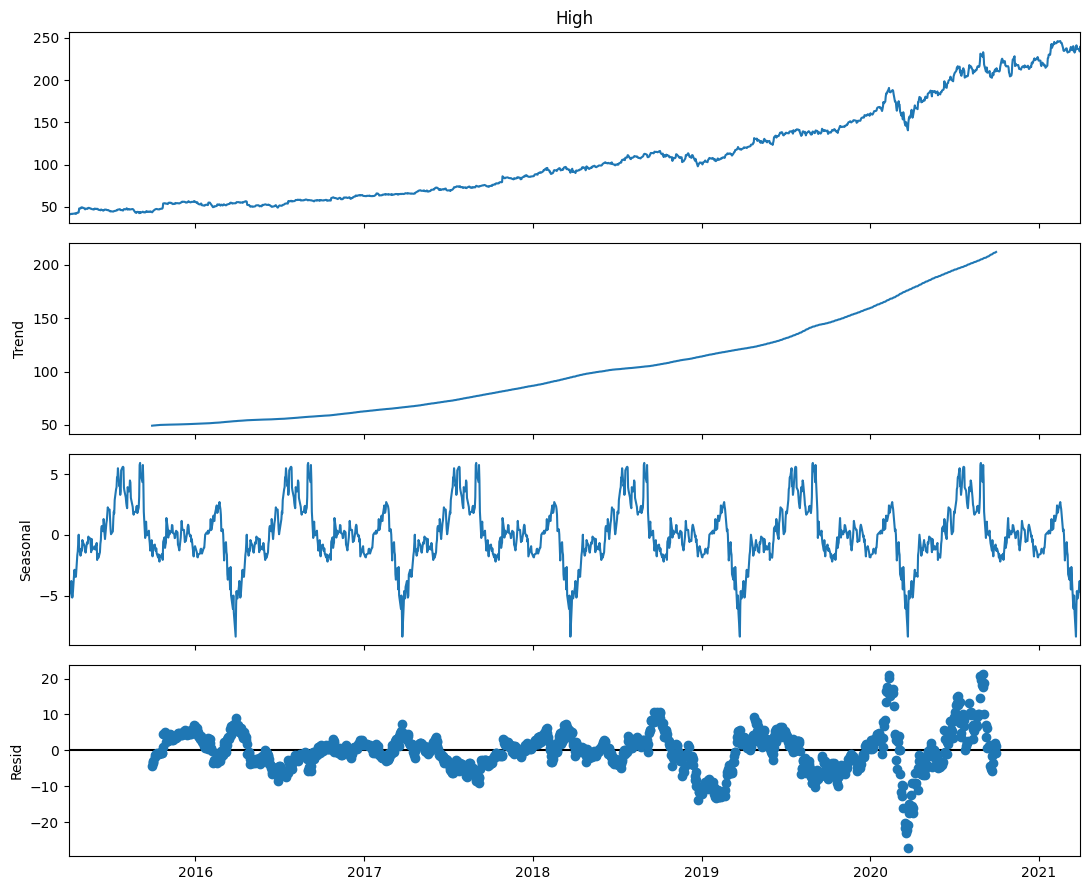

In [9]:
# importing the seasonal_decompose function from statsmodelьs
from statsmodels.tsa.seasonal import seasonal_decompose, STL
 
# setting the size of the graph
from pylab import rcParams
rcParams['figure.figsize'] = 11, 9
 
# applying the function to the data
decompose = seasonal_decompose(series, period=251)
decompose.plot()
 
plt.show()

In [10]:
train = series.loc[:'2019-12-31']
test = series.loc['2020-01-02':]

In [11]:
sarima_model = SARIMAX(train, order=(5,2,2), # плохие варианты (5,6,2) (6,5,2)
                       seasonal_order=(1,1,1,12), 
                       enforce_stationarity = False) # принудитеьлно учитывать стационарность временного ряда) 
sarima_fit = sarima_model.fit()

In [12]:
# Прогноз на длину тестовой выборки
forecast = sarima_fit.get_forecast(steps=len(test), index=test.index) 

In [13]:
forecast_mean = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

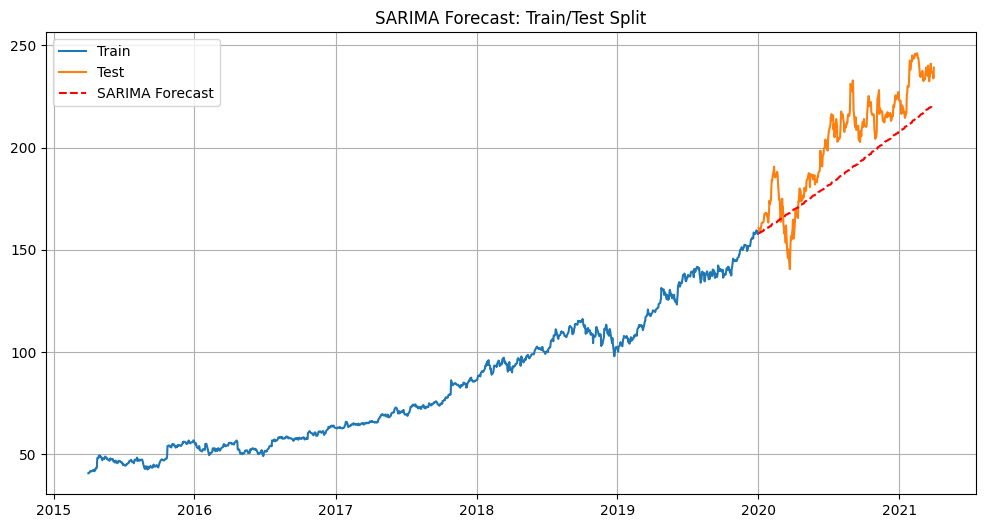

In [14]:
plt.figure(figsize=(12, 6))
plt.plot(train, label='Train')
plt.plot(test, label='Test')
plt.plot(forecast_mean, label='SARIMA Forecast', linestyle='--', color='red')  # Явное указание цвета

plt.title('SARIMA Forecast: Train/Test Split')
plt.legend()
plt.grid(True)
plt.show()

In [16]:
sarima_fit.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                       
============================================================================================
Dep. Variable:                                 High   No. Observations:                 1197
Model:             SARIMAX(5, 2, 2)x(1, 1, [1], 12)   Log Likelihood               -1719.095
Date:                              Thu, 03 Apr 2025   AIC                           3458.191
Time:                                      19:55:01   BIC                           3508.804
Sample:                                           0   HQIC                          3477.284
                                             - 1197                                         
Covariance Type:                                opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.9827      0.048    -20.377      0.000      -1.077      -0.888
ar.L2         -0.0551      0.032     -1.723      0.085      -0.118       0.008
ar.L3         -0.0795      0.035     -2.267      0.023      -0.148      -0.011
ar.L4         -0.0902      0.034     -2.639      0.008      -0.157      -0.023
ar.L5         -0.0485      0.028     -1.758      0.079      -0.103       0.006
ma.L1         -0.0351      0.046     -0.767      0.443      -0.125       0.055
ma.L2         -0.9629      0.044    -21.730      0.000      -1.050      -0.876
ar.S.L12   -1.181e-05      0.018     -0.001      0.999      -0.035       0.035
ma.S.L12      -0.9841      0.015    -66.494      0.000      -1.013      -0.955
sigma2         1.0724      0.031     34.815      0.000       1.012       1.133
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):              1804.01
Prob(Q):                              0.95   Prob(JB):                         0.00
Heteroskedasticity (H):               4.08   Skew:                             0.02
Prob(H) (two-sided):                  0.00   Kurtosis:                         9.09
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [1]:
# Подготовка данных для LSTM
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(series.values.reshape(-1,1))

NameError: name 'MinMaxScaler' is not defined

In [ ]:
def create_sequences(data, seq_length):
    sequences, labels = [], []
    for i in range(len(data) - seq_length):
        sequences.append(data[i:i+seq_length])
        labels.append(data[i+seq_length])
    return np.array(sequences), np.array(labels).reshape(-1,1)



In [2]:
seq_length = 50
X, y = create_sequences(data_scaled, seq_length)


NameError: name 'create_sequences' is not defined

In [3]:
split = int(len(X) * 0.8)
X_train, X_test, y_train, y_test = X[:split], X[split:], y[:split], y[split:]

NameError: name 'X' is not defined

In [4]:

model_lstm = Sequential([
    LSTM(100, return_sequences=True, input_shape=(seq_length, 1)),
    Dropout(0.2),
    LSTM(100, return_sequences=True),
    Dropout(0.2),
    LSTM(50, return_sequences=False),
    Dense(units=1, activation = "linear")
])

NameError: name 'Sequential' is not defined

In [5]:
model_lstm.compile(optimizer=Adam(learning_rate=0.001), loss='mse')
model_lstm.fit(X_train, y_train, epochs=10, batch_size=16, validation_data=(X_test, y_test))

NameError: name 'model_lstm' is not defined

In [6]:
# Прогноз LSTM
predictions = model_lstm.predict(X_test)
predictions = scaler.inverse_transform(predictions)
y_test_actual = scaler.inverse_transform(y_test)

NameError: name 'model_lstm' is not defined

In [ ]:
# Построение графика
plt.figure(figsize=(12, 6))
plt.plot(series.index[:split+seq_length], series.values[:split+seq_length], label='Обучающие данные')
plt.plot(series.index[split+seq_length:], y_test_actual, label='Тестовые данные')
plt.plot(series.index[split+seq_length:], predictions, label='Прогноз (LSTM)')
plt.legend()
plt.title("LSTM Forecast")
plt.xlabel("Дата")
plt.ylabel("Цена")
plt.show()